> **Portfolio summary:** Mean-variance vs Mean-VaR vs Mean-CVaR portfolio optimisation, compared out of sample (group project).
>
> [Project README](README.md) · [Back to the portfolio](../README.md)

# Group Project: Comparing Portfolio Optimisation Strategies

## Mean-Variance · Mean-VaR · Mean-CVaR · Naïve 1/N

| Parameter | Value |
|---|---|
| **Assets** | AAPL · MSFT · GOOGL · AMZN · NVDA |
| **Investment horizon** | Daily (1 business day) |
| **Estimation window M** | 252 trading days (≈ 1 year) |
| **Target annualised return** | 12% |
| **Total trading days** | 1,500 (≈ 6 years, simulated) |
| **Risk level α** | 5% (95% VaR / CVaR) |
| **Strategies** | Mean-Variance · Mean-VaR · Mean-CVaR · Naïve 1/N |

---

### Input Parameter Approach (Justification)

We use **rolling sample estimators** for all three optimisation problems:

- **Expected returns** μ̂: Rolling sample mean over the M-day window. Simple, unbiased, and widely used as a baseline. Alternative: GARCH-based forecasts (explored in Day 4).
- **Covariance matrix** Σ̂: Rolling sample covariance (unbiased, Bessel-corrected). We add a small ridge (`+ ε I`) for numerical stability.
- **Return scenarios for VaR/CVaR**: The full M×N return matrix from the estimation window. Empirical scenarios make no distributional assumption, allowing CVaR to capture fat tails and skewness naturally. VaR optimisation is heuristic (non-convex); CVaR is solved as a linear programme (Rockafellar & Uryasev 2000).

This unified approach ensures a **fair apples-to-apples comparison**: all four strategies observe the same information set at each rebalancing date.

---

### Evaluation Criteria (Justification)

Because the strategies differ in what risk metric they minimise, we evaluate on **multiple dimensions**:

| Metric | Why it matters |
|---|---|
| **Annualised Return** | Primary reward |
| **Annualised Std Dev** | Penalises symmetric risk |
| **Sharpe Ratio** | Risk-adjusted return (variance-based) |
| **Sortino Ratio** | Risk-adjusted return (downside-only); favours CVaR/VaR strategies |
| **Calmar Ratio** | Return per unit max drawdown; captures extreme-loss risk |
| **Realised 95% VaR** | Did the VaR strategy actually reduce tail risk? |
| **Realised 95% CVaR** | Did the CVaR strategy actually reduce expected shortfall? |
| **Max Drawdown** | Largest peak-to-trough loss |
| **Turnover** | Practical implementability |

Using multiple metrics prevents cherry-picking: a strategy optimal by one criterion may be inferior by another.

## 1. Imports and Configuration

In [1]:
import sys, subprocess, importlib
subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "--quiet",
     "numpy", "scipy", "matplotlib", "pandas", "cvxpy", "seaborn"],
    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
)
importlib.invalidate_caches()

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.optimize import minimize
import cvxpy as cp
import time

rng = np.random.default_rng(42)
plt.rcParams.update({
    'figure.dpi'        : 120,
    'font.size'         : 10,
    'axes.titlesize'    : 11,
    'axes.labelsize'    : 10,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.grid'         : True,
    'grid.alpha'        : 0.25,
    'grid.linestyle'    : '--',
    'legend.framealpha' : 0.85,
})

# ── Global parameters
STOCKS       = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA']
N            = len(STOCKS)
N_DAYS       = 1500          # ~6 years of trading days
M            = 252           # estimation window
ALPHA        = 0.05          # tail probability for VaR / CVaR (95% level)
TARGET_ANN   = 0.12          # 12% annualised target return
TARGET_DAILY = TARGET_ANN / 252

STRATEGY_KEYS   = ['MV', 'VaR', 'CVaR', 'Naive']
STRATEGY_LABELS = {
    'MV'    : 'Mean-Variance',
    'VaR'   : 'Mean-VaR',
    'CVaR'  : 'Mean-CVaR',
    'Naive' : 'Naïve 1/N',
}
COLORS = {
    'MV'    : '#1f77b4',
    'VaR'   : '#d62728',
    'CVaR'  : '#ff7f0e',
    'Naive' : '#2ca02c',
}
LINESTYLES = {'MV': '-', 'VaR': '--', 'CVaR': '-.', 'Naive': ':'}
MARKERS    = {'MV': 'o', 'VaR': '^', 'CVaR': 's', 'Naive': '*'}

print('Libraries loaded.')
print(f'  Assets           : {STOCKS}')
print(f'  Estimation window: M = {M} days')
print(f'  Target return    : {TARGET_ANN*100:.0f}% p.a.  ({TARGET_DAILY*100:.4f}% per day)')
print(f'  Tail probability : alpha = {ALPHA} (95% VaR/CVaR)')

Libraries loaded.
  Assets           : ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA']
  Estimation window: M = 252 days
  Target return    : 12% p.a.  (0.0476% per day)
  Tail probability : alpha = 0.05 (95% VaR/CVaR)

## 2. Data Generation

We simulate the same 5 assets as Day 4 using correlated GBM with a GARCH(1,1) common volatility factor. This keeps the Day 8 comparison consistent with the Day 4 mean-variance framework. All code is drop-in compatible with real data — replace this cell with `yf.download(...)`.

In [2]:
# Annualised drift and vol (roughly calibrated to 2018-2024)
mu_ann  = np.array([0.18, 0.22, 0.17, 0.20, 0.35])  # AAPL MSFT GOOGL AMZN NVDA
sig_ann = np.array([0.25, 0.27, 0.28, 0.30, 0.45])

mu_d  = mu_ann  / 252
sig_d = sig_ann / np.sqrt(252)

# Correlation: tech-tech high, fin-fin moderate, cross low
CORR = np.array([
    #AAPL  MSFT  GOOGL AMZN  NVDA
    [1.00, 0.75, 0.72, 0.68, 0.60],   # AAPL
    [0.75, 1.00, 0.70, 0.65, 0.62],   # MSFT
    [0.72, 0.70, 1.00, 0.66, 0.58],   # GOOGL
    [0.68, 0.65, 0.66, 1.00, 0.55],   # AMZN
    [0.60, 0.62, 0.58, 0.55, 1.00],   # NVDA
])

COV_D = np.outer(sig_d, sig_d) * CORR
L     = np.linalg.cholesky(COV_D)

# Simulate correlated shocks
raw = rng.standard_normal((N_DAYS, N)) @ L.T

# GARCH(1,1) common volatility factor
omega_g, alpha_g, beta_g = 0.05, 0.15, 0.80
ht = np.ones(N_DAYS)
for t in range(1, N_DAYS):
    eps_norm = raw[t-1, 0] / sig_d[0]
    ht[t]    = omega_g + alpha_g * eps_norm**2 + beta_g * ht[t-1]
ht = np.sqrt(np.clip(ht, 1e-6, 10))

ret_arr = raw * ht.reshape(-1, 1) + mu_d

DATES     = pd.date_range('2018-01-02', periods=N_DAYS, freq='B')
daily_ret = pd.DataFrame(ret_arr, index=DATES, columns=STOCKS)
prices    = 100 * (1 + daily_ret).cumprod()

stats_df = pd.DataFrame({
    'Ann. Drift (%)'    : (daily_ret.mean() * 252 * 100).round(2),
    'Ann. Vol (%)'      : (daily_ret.std()  * np.sqrt(252) * 100).round(2),
    'Skewness'          : daily_ret.skew().round(3),
    'Excess Kurt.'      : daily_ret.kurt().round(3),
    'Min Daily Ret (%)' : (daily_ret.min() * 100).round(2),
    'Max Daily Ret (%)' : (daily_ret.max() * 100).round(2),
})
print('Simulated daily return statistics:\n')
print(stats_df.to_string())
print(f'\nDate range  : {DATES[0].date()} to {DATES[-1].date()}  ({N_DAYS} trading days)')
print(f'OOS periods : {N_DAYS - M - 1}')

Simulated daily return statistics:

       Ann. Drift (%)  Ann. Vol (%)  Skewness  Excess Kurt.  Min Daily Ret (%)  Max Daily Ret (%)
AAPL            11.22         25.54    -0.105         0.143              -5.29               5.50
MSFT            22.56         28.00    -0.084         0.251              -5.95               6.05
GOOGL            9.99         27.59    -0.121         0.367              -6.41               6.24
AMZN            14.92         30.82    -0.092         0.516              -7.75               8.24
NVDA            24.16         45.83    -0.052         0.196             -11.04               9.73

Date range  : 2018-01-02 to 2023-10-02  (1500 trading days)
OOS periods : 1247

## 3. Exploratory Data Analysis

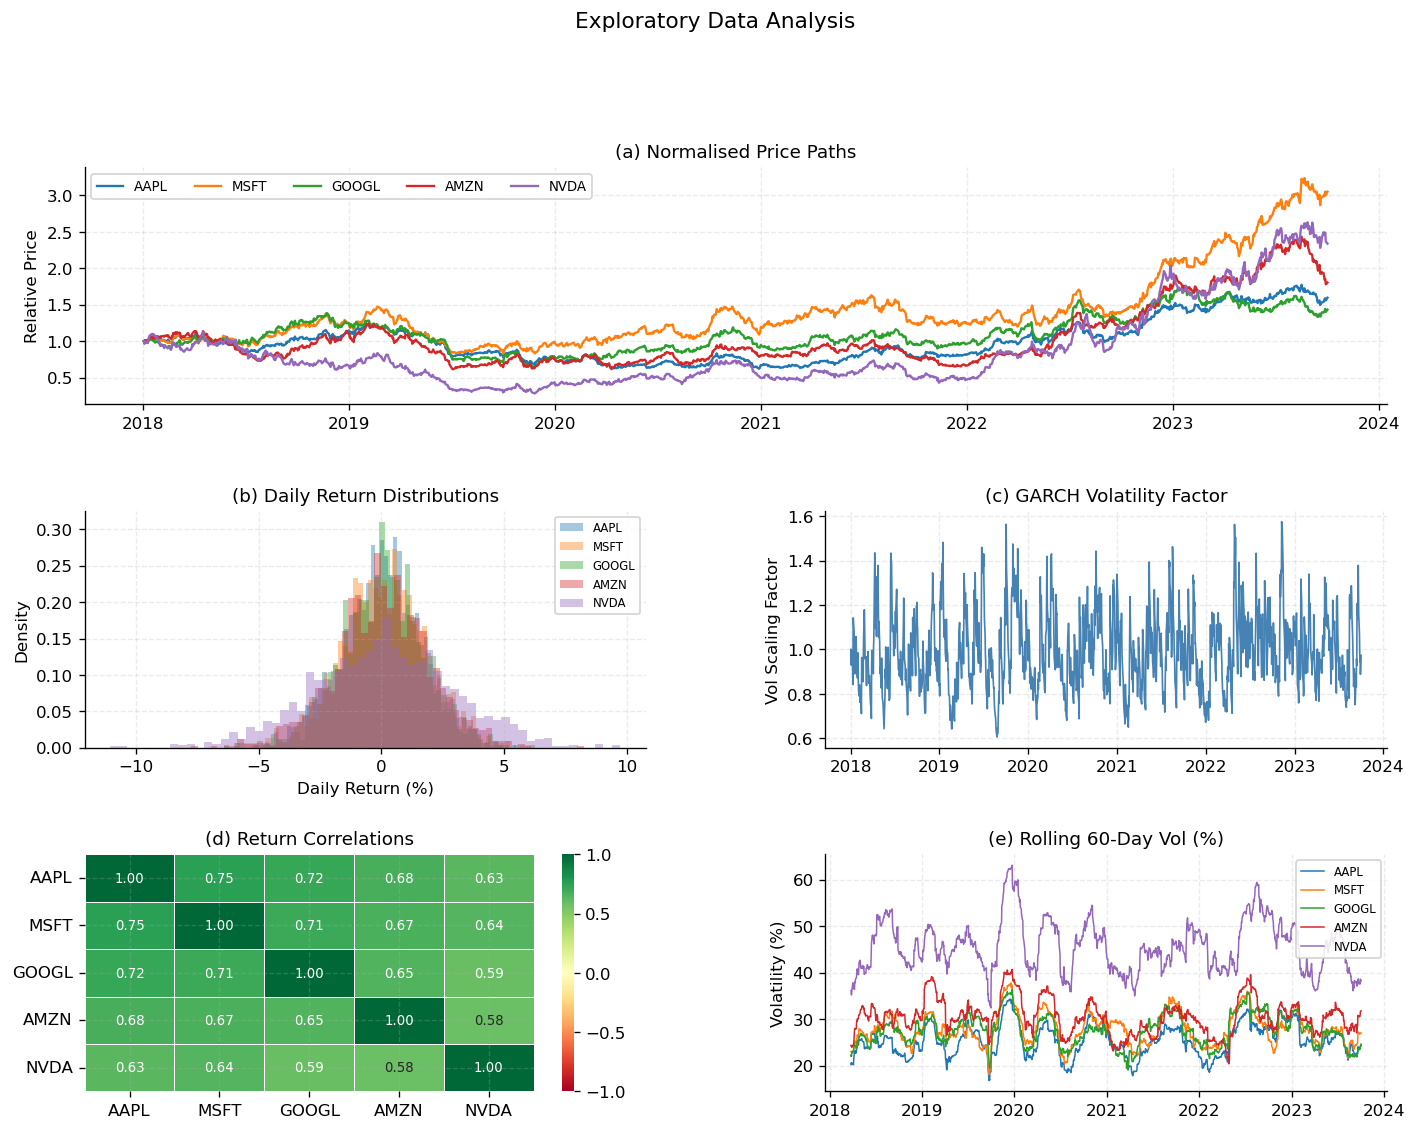

In [3]:
pal = sns.color_palette('tab10', N)

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.32)

# (a) Normalised prices
ax0 = fig.add_subplot(gs[0, :])
norm_prices = prices / prices.iloc[0]
for i, s in enumerate(STOCKS):
    ax0.plot(norm_prices.index, norm_prices[s], lw=1.4, label=s, color=pal[i])
ax0.set_title('(a) Normalised Price Paths')
ax0.set_ylabel('Relative Price')
ax0.legend(ncol=7, fontsize=8)

# (b) Return distributions
ax1 = fig.add_subplot(gs[1, 0])
for i, s in enumerate(STOCKS):
    ax1.hist(daily_ret[s]*100, bins=60, alpha=0.4, density=True, label=s, color=pal[i])
ax1.set_title('(b) Daily Return Distributions')
ax1.set_xlabel('Daily Return (%)')
ax1.set_ylabel('Density')
ax1.legend(fontsize=7)

# (c) GARCH vol factor
ax2 = fig.add_subplot(gs[1, 1])
ax2.plot(DATES, ht, color='steelblue', lw=1.0)
ax2.set_title('(c) GARCH Volatility Factor')
ax2.set_ylabel('Vol Scaling Factor')

# (d) Correlation heatmap
ax3 = fig.add_subplot(gs[2, 0])
sns.heatmap(daily_ret.corr(), annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, ax=ax3, linewidths=0.5, annot_kws={'size': 8})
ax3.set_title('(d) Return Correlations')

# (e) Rolling 60-day vol
ax4 = fig.add_subplot(gs[2, 1])
for i, s in enumerate(STOCKS):
    rv = daily_ret[s].rolling(60).std() * np.sqrt(252) * 100
    ax4.plot(rv.index, rv, lw=0.9, label=s, color=pal[i])
ax4.set_title('(e) Rolling 60-Day Vol (%)')
ax4.set_ylabel('Volatility (%)')
ax4.legend(fontsize=7)

plt.suptitle('Exploratory Data Analysis', fontsize=13, y=1.01)
plt.show()

## 4. Portfolio Optimisation Solvers

### Risk Measures

Given portfolio losses $\mathcal{L} = -\mathbf{w}^\top \mathbf{r}$ from empirical return matrix $R$ (shape $T \times N$):

$$\text{VaR}_\alpha = \text{quantile}_{1-\alpha}(\mathcal{L})$$

$$\text{CVaR}_\alpha = \mathbb{E}[\mathcal{L} \mid \mathcal{L} \geq \text{VaR}_\alpha]$$

### Mean-Variance (convex QP)
$$\min_{\mathbf{w}} \mathbf{w}^\top \hat{\Sigma} \mathbf{w} \quad \text{s.t.} \quad \mathbf{w}^\top \hat{\mu} \geq \mu^*, \; \mathbf{1}^\top \mathbf{w} = 1, \; \mathbf{w} \geq 0$$

### Mean-CVaR (convex LP — Rockafellar & Uryasev 2000)
$$\min_{\mathbf{w}, \zeta, \boldsymbol{\eta}} \zeta + \frac{1}{\alpha T} \sum_{t=1}^T \eta_t \quad \text{s.t.} \quad \eta_t \geq -\mathbf{r}_t^\top \mathbf{w} - \zeta, \; \eta_t \geq 0, \; \mathbf{w}^\top \hat{\mu} \geq \mu^*, \; \mathbf{1}^\top \mathbf{w} = 1, \; \mathbf{w} \geq 0$$

### Mean-VaR (non-convex — SLSQP with random restarts)
VaR is non-convex and discontinuous; we minimise empirical VaR via SLSQP with multiple random starting points.

In [4]:
# ── Risk measure helpers ──────────────────────────────────────────────────────

def var_emp(losses, alpha):
    """Empirical VaR at tail probability alpha (loss exceeded with prob alpha)."""
    return float(np.quantile(losses, 1 - alpha))

def cvar_emp(losses, alpha):
    """Empirical CVaR (Expected Shortfall) at tail probability alpha."""
    q    = var_emp(losses, alpha)
    tail = losses[losses >= q]
    return float(tail.mean()) if len(tail) else q


# ── Optimisation solvers ──────────────────────────────────────────────────────

def solve_mv(R, mu_target, ridge=1e-8):
    """
    Mean-Variance: minimise portfolio variance subject to a return target.
    Uses sample covariance with small ridge for numerical stability.
    No-short constraint (w >= 0).
    """
    n   = R.shape[1]
    mu  = R.mean(0)
    Sig = np.cov(R, rowvar=False) + ridge * np.eye(n)
    x   = cp.Variable(n, nonneg=True)
    prob = cp.Problem(
        cp.Minimize(cp.quad_form(x, Sig)),
        [x @ mu >= mu_target, cp.sum(x) == 1]
    )
    prob.solve(solver=cp.CLARABEL, verbose=False)
    if x.value is None or np.any(np.isnan(x.value)):
        return np.ones(n) / n   # fallback to equal weights
    return np.clip(x.value, 0, None)


def solve_cvar(R, mu_target, alpha):
    """
    Mean-CVaR: minimise CVaR (= ES) using the Rockafellar-Uryasev LP.
    Scenario-based: uses all T rows of R as scenarios.
    No-short constraint (w >= 0).
    """
    T, n  = R.shape
    mu    = R.mean(0)
    x     = cp.Variable(n, nonneg=True)
    zeta  = cp.Variable()                 # VaR level
    eta   = cp.Variable(T, nonneg=True)   # excess losses above VaR
    prob  = cp.Problem(
        cp.Minimize(zeta + (1.0 / (alpha * T)) * cp.sum(eta)),
        [
            eta >= -R @ x - zeta,         # eta_t >= loss_t - zeta
            x @ mu >= mu_target,
            cp.sum(x) == 1,
        ]
    )
    prob.solve(solver=cp.CLARABEL, verbose=False)
    if x.value is None or np.any(np.isnan(x.value)):
        return np.ones(n) / n
    return np.clip(x.value, 0, None)


def solve_var(R, mu_target, alpha, n_restarts=5):
    """
    Mean-VaR: minimise empirical VaR via SLSQP with random restarts.
    VaR is non-convex and non-differentiable; multiple starts help escape
    local optima and flat regions.
    No-short constraint (w >= 0).
    """
    T, n = R.shape
    mu   = R.mean(0)

    def obj(w):
        return var_emp(-R @ w, alpha)

    constraints = [
        {'type': 'eq',   'fun': lambda w: w.sum() - 1},
        {'type': 'ineq', 'fun': lambda w: w @ mu - mu_target},
    ]
    bounds = [(0, 1)] * n

    best_val, best_w = np.inf, None
    for _ in range(n_restarts):
        w0  = rng.dirichlet(np.ones(n))
        res = minimize(obj, w0, method='SLSQP', bounds=bounds,
                       constraints=constraints,
                       options={'ftol': 1e-9, 'maxiter': 500})
        if res.success and res.fun < best_val:
            best_val, best_w = res.fun, res.x

    if best_w is None:
        return np.ones(n) / n
    return np.clip(best_w, 0, None)


# ── Performance statistics ────────────────────────────────────────────────────

def compute_metrics(r_arr, ann=252, alpha=ALPHA):
    """Full set of out-of-sample performance metrics."""
    mu_ann  = r_arr.mean() * ann
    std_ann = r_arr.std()  * np.sqrt(ann)
    sharpe  = mu_ann / std_ann if std_ann > 0 else np.nan
    wealth  = np.cumprod(1 + r_arr)
    roll_mx = np.maximum.accumulate(wealth)
    max_dd  = ((wealth - roll_mx) / roll_mx).min()
    calmar  = -mu_ann / max_dd if max_dd < 0 else np.nan
    down    = r_arr[r_arr < 0].std() * np.sqrt(ann)
    sortino = mu_ann / down if down > 0 else np.nan
    losses  = -r_arr
    real_var  = var_emp(losses, alpha)
    real_cvar = cvar_emp(losses, alpha)
    return {
        'Ann. Return (%)'    : round(mu_ann  * 100, 2),
        'Ann. Std Dev (%)'   : round(std_ann * 100, 2),
        'Sharpe Ratio'       : round(sharpe,    3),
        'Sortino Ratio'      : round(sortino,   3),
        'Calmar Ratio'       : round(calmar,    3),
        'Max Drawdown (%)'   : round(max_dd  * 100, 2),
        'Realised VaR5% (%)' : round(real_var  * 100, 3),
        'Realised CVaR5% (%)': round(real_cvar * 100, 3),
    }

print('Solvers and metrics defined:')
print('  solve_mv    — Mean-Variance (CLARABEL QP)')
print('  solve_cvar  — Mean-CVaR (CLARABEL LP, Rockafellar-Uryasev)')
print('  solve_var   — Mean-VaR  (SLSQP, 20 random restarts)')
print('  compute_metrics — 8 evaluation metrics')

Solvers and metrics defined:
  solve_mv    — Mean-Variance (CLARABEL QP)
  solve_cvar  — Mean-CVaR (CLARABEL LP, Rockafellar-Uryasev)
  solve_var   — Mean-VaR  (SLSQP, 20 random restarts)
  compute_metrics — 8 evaluation metrics

## 5. Rolling Out-of-Sample Backtest

**Protocol:** At each rebalancing date $t = M, M+1, \ldots, T-2$:

1. Estimate inputs from returns in $[t-M,\, t-1]$ (same window for all strategies)
2. Solve MV, Mean-VaR, Mean-CVaR, and compute 1/N weights
3. Record the realised one-day return at $t+1$ for all four strategies

⚠️ **Note:** Mean-VaR uses random restarts (heuristic), so the backtest will take a few minutes.

In [5]:
t_start  = time.time()
n_steps  = N_DAYS - M - 1
print(f'Rolling backtest | M={M} | {n_steps} OOS steps | {N} assets')
print('(Mean-VaR with random restarts — estimated time ~3-5 min)\n')

oos_ret  = {k: [] for k in STRATEGY_KEYS}
wt_hist  = {k: [] for k in STRATEGY_KEYS}

for step, t in enumerate(range(M, N_DAYS - 1)):
    R_win = daily_ret.iloc[t - M : t].values   # M × N return matrix

    # Solve all three optimisations
    w_mv   = solve_mv(R_win,   TARGET_DAILY)
    w_cvar = solve_cvar(R_win, TARGET_DAILY, ALPHA)
    w_var  = solve_var(R_win,  TARGET_DAILY, ALPHA)
    w_1n   = np.ones(N) / N

    # Realised return at t+1
    r_next = daily_ret.iloc[t + 1].values
    oos_ret['MV'].append(   float(w_mv   @ r_next))
    oos_ret['CVaR'].append( float(w_cvar @ r_next))
    oos_ret['VaR'].append(  float(w_var  @ r_next))
    oos_ret['Naive'].append(float(w_1n   @ r_next))

    for k, w in zip(STRATEGY_KEYS, [w_mv, w_var, w_cvar, w_1n]):
        wt_hist[k].append(w.copy())

    if step % 200 == 0 or step == n_steps - 1:
        elapsed = time.time() - t_start
        rate    = (step + 1) / max(elapsed, 1e-6)
        eta     = (n_steps - step - 1) / rate
        print(f'  step {step+1:4d}/{n_steps}  |  {elapsed:.0f}s elapsed  |  ETA {eta:.0f}s')

oos_ret  = {k: np.array(v) for k, v in oos_ret.items()}
wt_hist  = {k: np.array(v) for k, v in wt_hist.items()}
OOS_DATES = daily_ret.index[M + 1 : M + 1 + len(oos_ret['Naive'])]

print(f'\nBacktest complete in {time.time()-t_start:.1f}s')
print(f'OOS observations per strategy: {len(oos_ret["Naive"])}')

Rolling backtest | M=252 | 1247 OOS steps | 5 assets
(Mean-VaR with random restarts — estimated time ~3-5 min)

  step    1/1247  |  1s elapsed  |  ETA 843s
  step  201/1247  |  93s elapsed  |  ETA 486s
  step  401/1247  |  149s elapsed  |  ETA 314s
  step  601/1247  |  272s elapsed  |  ETA 293s
  step  801/1247  |  379s elapsed  |  ETA 211s
  step 1001/1247  |  506s elapsed  |  ETA 124s
  step 1201/1247  |  634s elapsed  |  ETA 24s
  step 1247/1247  |  663s elapsed  |  ETA 0s

Backtest complete in 662.8s
OOS observations per strategy: 1247

## 6. Out-of-Sample Performance Statistics

In [6]:
perf = pd.DataFrame(
    {STRATEGY_LABELS[k]: compute_metrics(oos_ret[k]) for k in STRATEGY_KEYS}
).T

pd.set_option('display.float_format', '{:.3f}'.format)
print('Out-of-Sample Performance Summary (annualised)\n')
print(perf.to_string())
print()

for col in ['Ann. Return (%)', 'Sharpe Ratio', 'Sortino Ratio',
            'Calmar Ratio', 'Realised CVaR5% (%)']:
    if col == 'Realised CVaR5% (%)':
        best = perf[col].idxmin()   # lower CVaR = better risk control
        print(f'  Lowest {col:<26}: {best}   ← best tail-risk control')
    elif col == 'Realised VaR5% (%)':
        best = perf[col].idxmin()
        print(f'  Lowest {col:<26}: {best}')
    else:
        best = perf[col].idxmax()
        print(f'  Best {col:<28}: {best}')

Out-of-Sample Performance Summary (annualised)

               Ann. Return (%)  Ann. Std Dev (%)  Sharpe Ratio  Sortino Ratio  Calmar Ratio  Max Drawdown (%)  Realised VaR5% (%)  Realised CVaR5% (%)
Mean-Variance           16.010            25.380         0.631          0.972         0.361           -44.350               2.637                3.448
Mean-VaR                14.970            25.740         0.581          0.908         0.312           -48.030               2.649                3.516
Mean-CVaR               18.420            25.610         0.719          1.113         0.429           -42.950               2.661                3.453
Naïve 1/N               18.460            27.060         0.682          1.065         0.371           -49.770               2.809                3.657

  Best Ann. Return (%)             : Naïve 1/N
  Best Sharpe Ratio                : Mean-CVaR
  Best Sortino Ratio               : Mean-CVaR
  Best Calmar Ratio                : Mean-CVaR
  Lowest

## 7. Cumulative Wealth and Drawdown

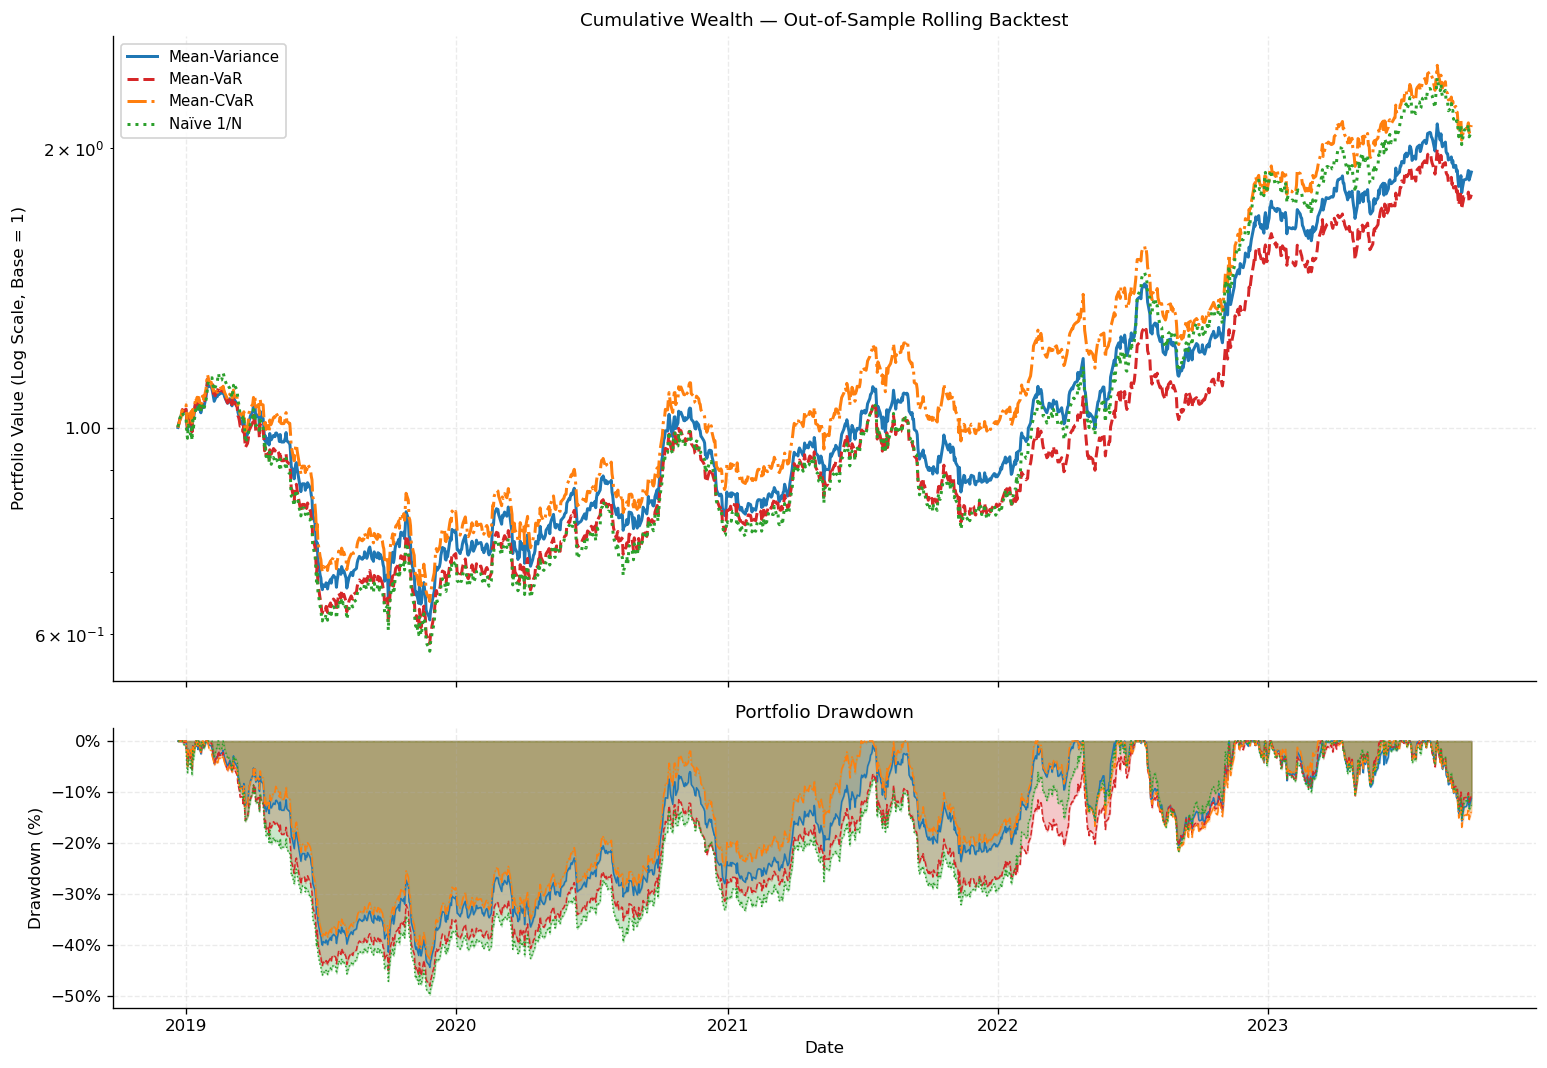

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9),
                         gridspec_kw={'height_ratios': [3, 1.3]}, sharex=True)

ax = axes[0]
for k in STRATEGY_KEYS:
    wealth = np.cumprod(1 + oos_ret[k])
    ax.plot(OOS_DATES, wealth, lw=1.8,
            color=COLORS[k], ls=LINESTYLES[k], label=STRATEGY_LABELS[k])
ax.set_yscale('log')
ax.set_ylabel('Portfolio Value (Log Scale, Base = 1)')
ax.set_title('Cumulative Wealth — Out-of-Sample Rolling Backtest')
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mtick.ScalarFormatter())

ax2 = axes[1]
for k in STRATEGY_KEYS:
    wealth   = np.cumprod(1 + oos_ret[k])
    roll_max = np.maximum.accumulate(wealth)
    dd       = (wealth - roll_max) / roll_max * 100
    ax2.fill_between(OOS_DATES, dd, 0, alpha=0.25, color=COLORS[k])
    ax2.plot(OOS_DATES, dd, lw=0.9, color=COLORS[k], ls=LINESTYLES[k])
ax2.set_ylabel('Drawdown (%)')
ax2.set_xlabel('Date')
ax2.set_title('Portfolio Drawdown')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
plt.show()

## 8. Mean–Standard Deviation Diagram

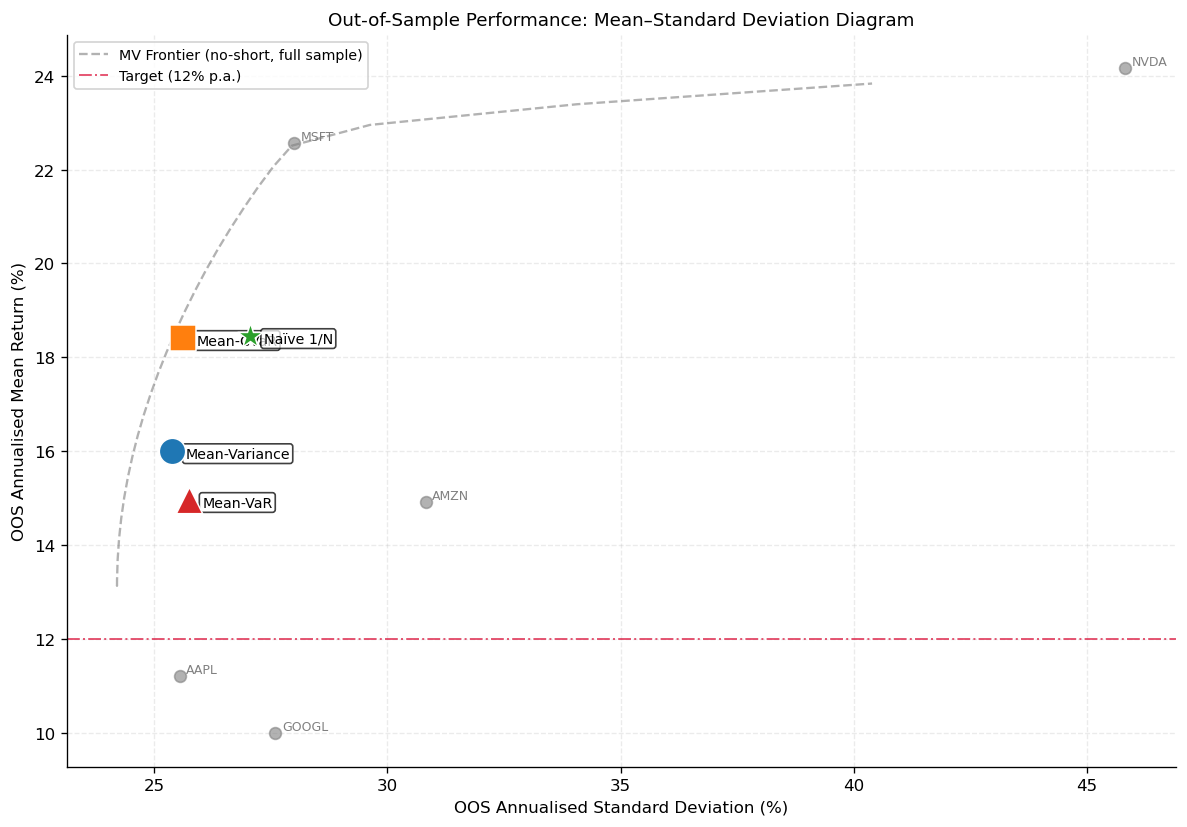

In [8]:
# Full-sample reference frontier (no-short)
mu_full  = daily_ret.mean().values * 252
cov_full = daily_ret.cov().values  * 252
std_full = np.sqrt(np.diag(cov_full))

def efficient_frontier(mu_vec, cov_mat, ret_range):
    vols, rets = [], []
    n  = len(mu_vec)
    w0 = np.ones(n) / n
    for tgt in ret_range:
        x   = cp.Variable(n, nonneg=True)
        con = [cp.sum(x) == 1, x @ mu_vec >= tgt]
        res = cp.Problem(cp.Minimize(cp.quad_form(x, cov_mat + 1e-8*np.eye(n))), con)
        res.solve(solver=cp.CLARABEL, verbose=False)
        if x.value is not None:
            vols.append(float(np.sqrt(x.value @ cov_mat @ x.value)))
            rets.append(float(x.value @ mu_vec))
    return np.array(vols), np.array(rets)

range_ns = np.linspace(0.04, 0.30, 60)
fv_ns, fr_ns = efficient_frontier(mu_full, cov_full, range_ns)

# OOS strategy scatter points
strat_pts = {k: (oos_ret[k].std() * np.sqrt(252) * 100,
                 oos_ret[k].mean() * 252 * 100)
             for k in STRATEGY_KEYS}

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(fv_ns*100, fr_ns*100, 'k--', lw=1.4, alpha=0.3, label='MV Frontier (no-short, full sample)')

for i, s in enumerate(STOCKS):
    ax.scatter(std_full[i]*100, mu_full[i]*100, color='grey', s=50, zorder=3, alpha=0.6)
    ax.annotate(s, (std_full[i]*100, mu_full[i]*100),
                textcoords='offset points', xytext=(4, 2), fontsize=7.5, color='grey')

for k in STRATEGY_KEYS:
    sd, mu_pt = strat_pts[k]
    ax.scatter(sd, mu_pt, color=COLORS[k], marker=MARKERS[k], s=250,
               zorder=6, edgecolors='white', linewidths=0.9)
    ax.annotate(STRATEGY_LABELS[k], (sd, mu_pt),
                textcoords='offset points', xytext=(8, -4), fontsize=8.5,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.75))

ax.axhline(TARGET_ANN*100, color='crimson', lw=1.2, ls='-.', alpha=0.7,
           label=f'Target ({TARGET_ANN*100:.0f}% p.a.)')
ax.set_xlabel('OOS Annualised Standard Deviation (%)')
ax.set_ylabel('OOS Annualised Mean Return (%)')
ax.set_title('Out-of-Sample Performance: Mean–Standard Deviation Diagram')
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

## 9. Tail Risk Comparison: Realised VaR and CVaR

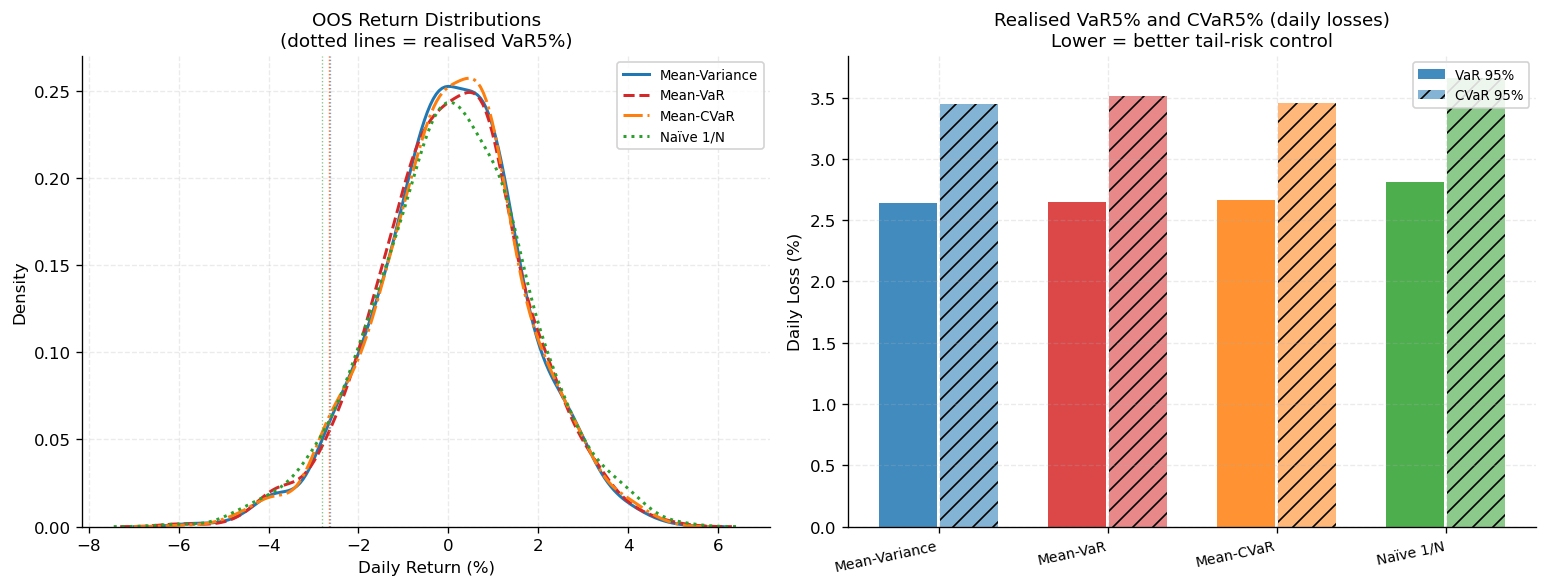

Realised daily VaR5% and CVaR5% (%):
  Mean-Variance       :  VaR5% = 2.637%   CVaR5% = 3.448%
  Mean-VaR            :  VaR5% = 2.649%   CVaR5% = 3.516%
  Mean-CVaR           :  VaR5% = 2.661%   CVaR5% = 3.453%
  Naïve 1/N           :  VaR5% = 2.809%   CVaR5% = 3.657%

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Return distributions with VaR/CVaR markers
ax = axes[0]
for k in STRATEGY_KEYS:
    r = oos_ret[k]
    sns.kdeplot(r*100, ax=ax, label=STRATEGY_LABELS[k],
                color=COLORS[k], ls=LINESTYLES[k], lw=1.8)
    v = var_emp(-r, ALPHA) * 100
    ax.axvline(-v, color=COLORS[k], lw=0.8, alpha=0.6, ls=':')
ax.set_xlabel('Daily Return (%)')
ax.set_ylabel('Density')
ax.set_title('OOS Return Distributions\n(dotted lines = realised VaR5%)')
ax.legend(fontsize=8)

# Panel 2: Bar chart of VaR vs CVaR by strategy
ax2 = axes[1]
labels  = [STRATEGY_LABELS[k] for k in STRATEGY_KEYS]
vars_   = [var_emp(-oos_ret[k], ALPHA)*100  for k in STRATEGY_KEYS]
cvars_  = [cvar_emp(-oos_ret[k], ALPHA)*100 for k in STRATEGY_KEYS]
x_pos   = np.arange(len(STRATEGY_KEYS))

ax2.bar(x_pos - 0.18, vars_,  0.34, label='VaR 95%',  alpha=0.85,
        color=[COLORS[k] for k in STRATEGY_KEYS])
ax2.bar(x_pos + 0.18, cvars_, 0.34, label='CVaR 95%', alpha=0.55,
        color=[COLORS[k] for k in STRATEGY_KEYS], hatch='//')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(labels, rotation=12, ha='right', fontsize=8.5)
ax2.set_ylabel('Daily Loss (%)')
ax2.set_title('Realised VaR5% and CVaR5% (daily losses)\nLower = better tail-risk control')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

print('Realised daily VaR5% and CVaR5% (%):')
for k in STRATEGY_KEYS:
    v = var_emp(-oos_ret[k], ALPHA)*100
    c = cvar_emp(-oos_ret[k], ALPHA)*100
    print(f'  {STRATEGY_LABELS[k]:<20}:  VaR5% = {v:.3f}%   CVaR5% = {c:.3f}%')

## 10. Portfolio Weight Dynamics

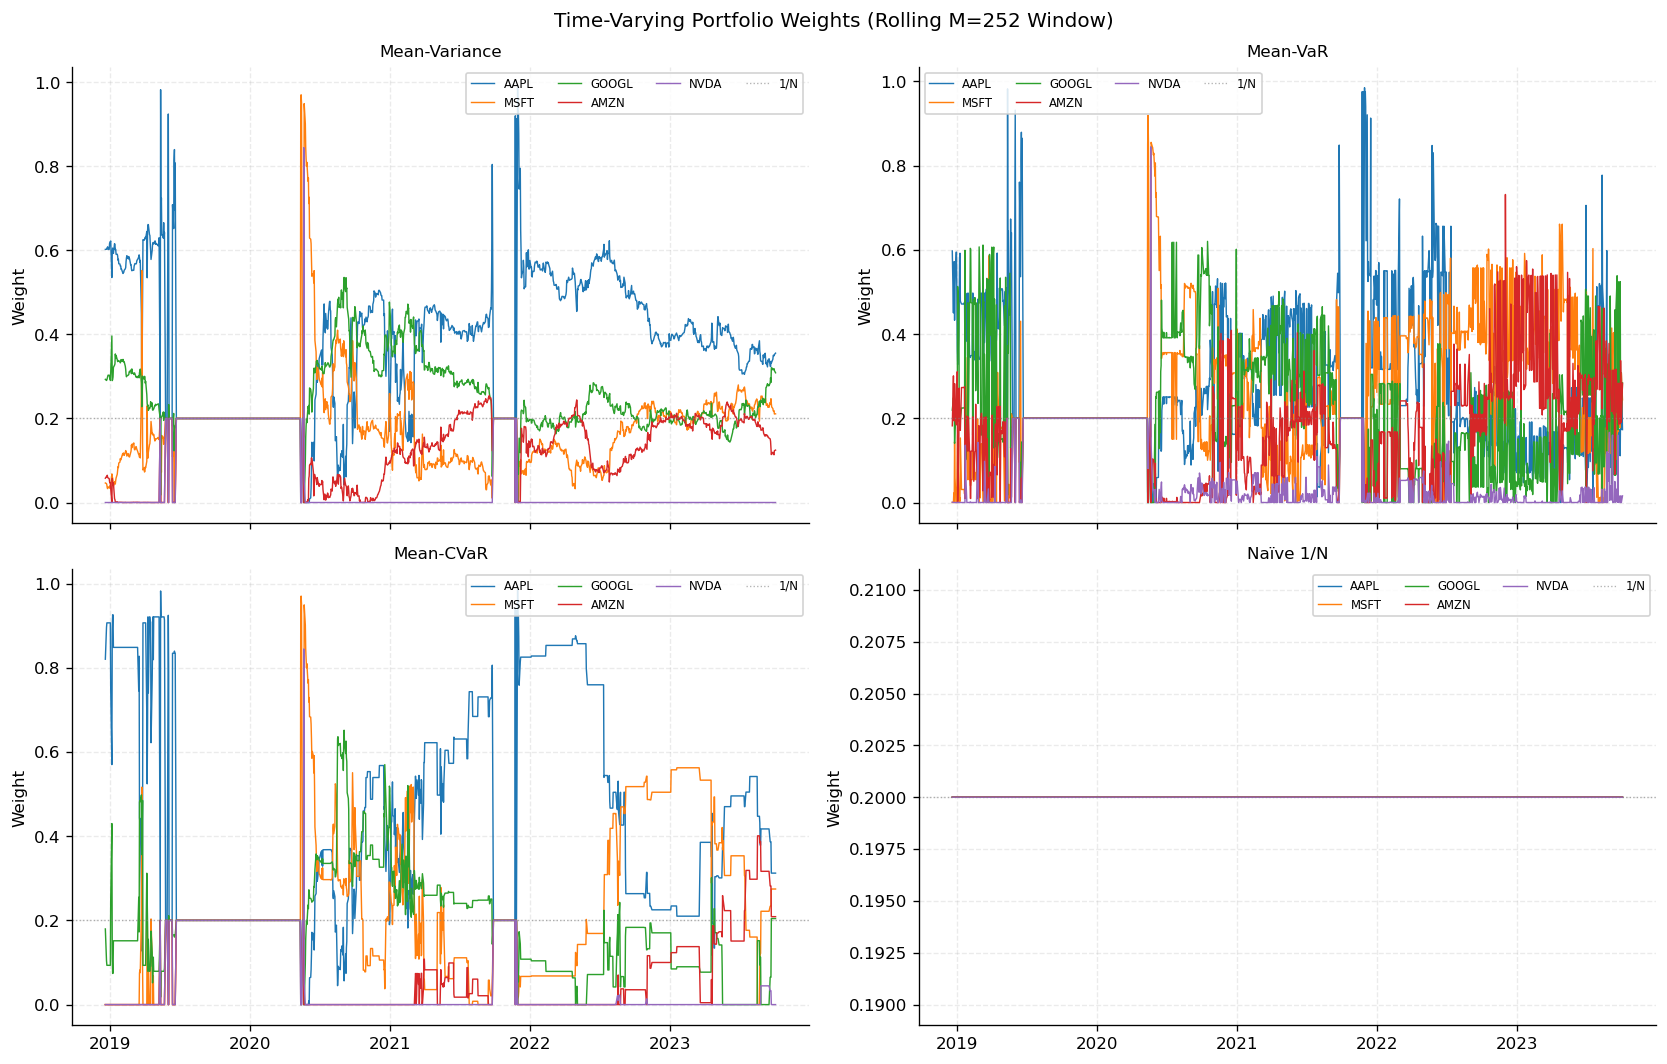

Average daily portfolio turnover (sum of |Δw|):
  Mean-Variance         : 0.0496
  Mean-VaR              : 0.2482
  Mean-CVaR             : 0.0555
  Naïve 1/N             : 0.0000

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

for ax, key in zip(axes.flat, STRATEGY_KEYS):
    w_arr = wt_hist[key]
    for i, s in enumerate(STOCKS):
        ax.plot(OOS_DATES, w_arr[:, i], lw=0.85, color=pal[i], label=s)
    ax.axhline(1/N, color='grey', lw=0.8, ls=':', alpha=0.6, label='1/N')
    ax.set_title(STRATEGY_LABELS[key], fontsize=10)
    ax.set_ylabel('Weight')
    ax.legend(fontsize=7, ncol=4)

plt.suptitle('Time-Varying Portfolio Weights (Rolling M=252 Window)', fontsize=12)
plt.tight_layout()
plt.show()

# Turnover summary
print('Average daily portfolio turnover (sum of |Δw|):')
for k in STRATEGY_KEYS:
    tov = np.abs(np.diff(wt_hist[k], axis=0)).sum(axis=1).mean()
    print(f'  {STRATEGY_LABELS[k]:<22}: {tov:.4f}')

## 11. Rolling Risk-Adjusted Performance

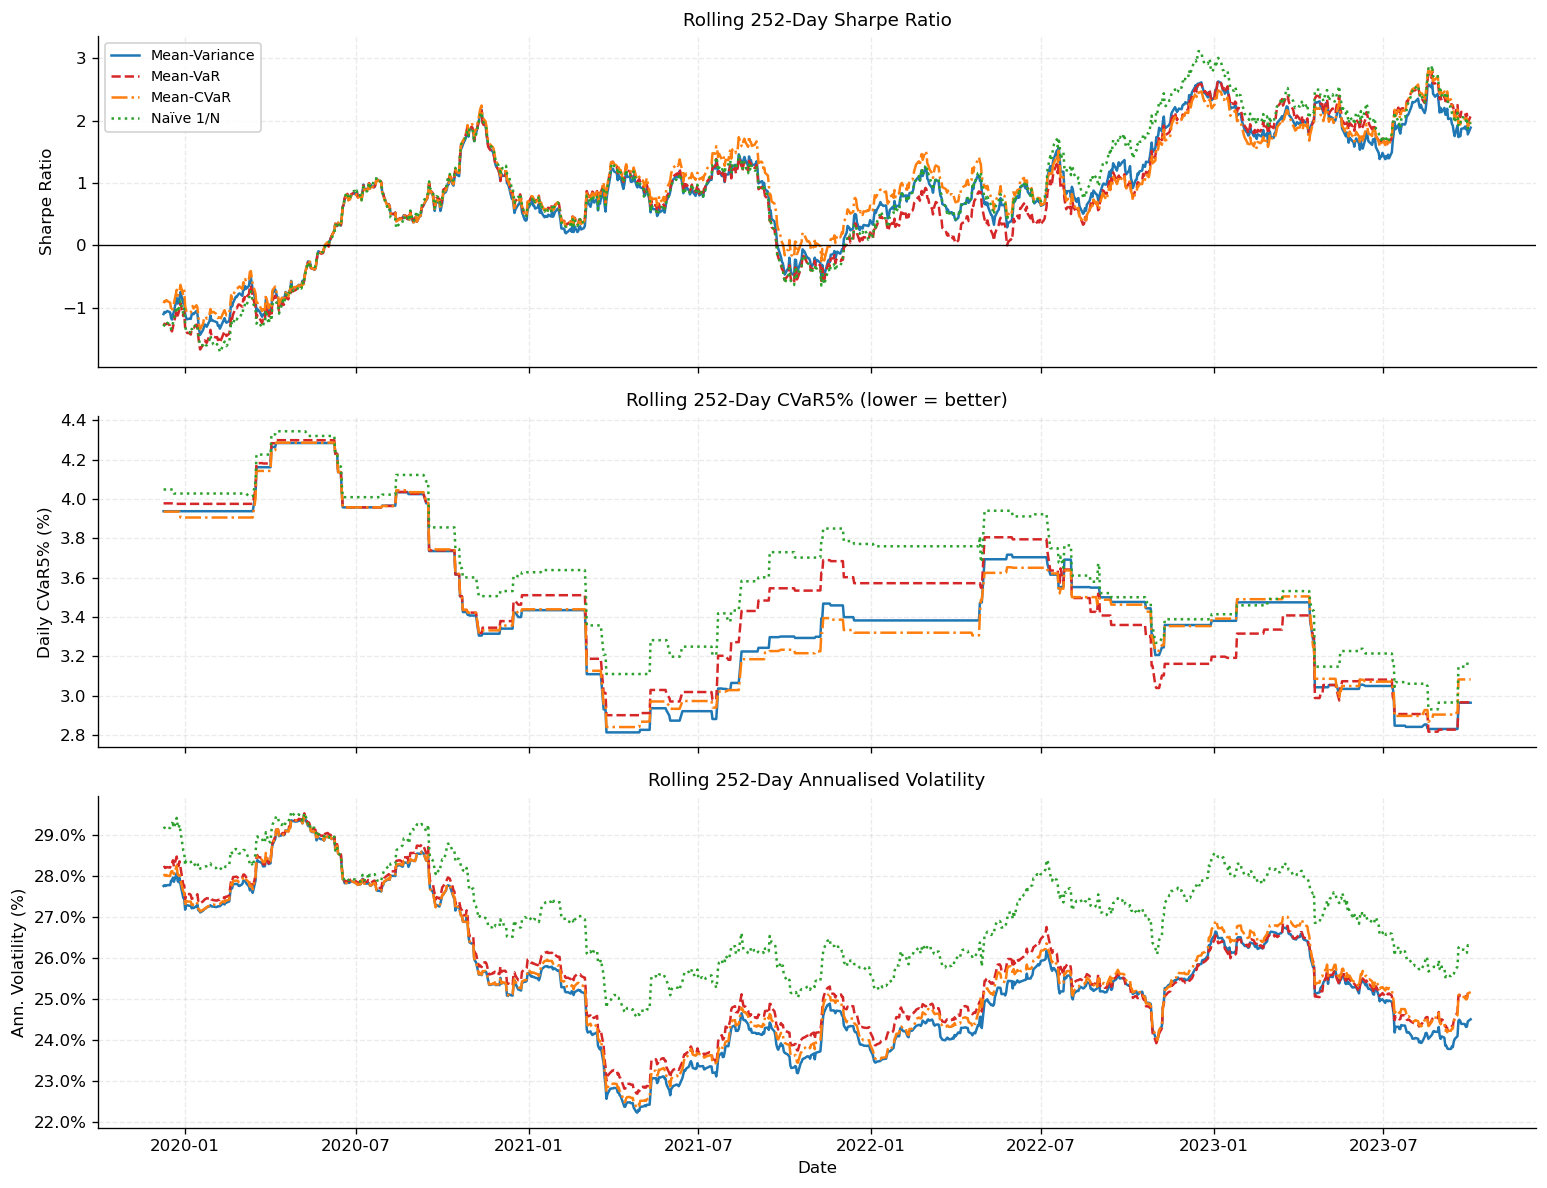

In [11]:
W = 252   # rolling window for metrics

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

# Rolling Sharpe
ax = axes[0]
for k in STRATEGY_KEYS:
    r  = pd.Series(oos_ret[k], index=OOS_DATES)
    rs = r.rolling(W).mean() / r.rolling(W).std() * np.sqrt(252)
    ax.plot(rs.index, rs, lw=1.5, color=COLORS[k], ls=LINESTYLES[k],
            label=STRATEGY_LABELS[k])
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('Sharpe Ratio')
ax.set_title(f'Rolling {W}-Day Sharpe Ratio')
ax.legend(fontsize=8.5)

# Rolling CVaR
ax2 = axes[1]
for k in STRATEGY_KEYS:
    r   = pd.Series(oos_ret[k], index=OOS_DATES)
    rcv = r.rolling(W).apply(
        lambda x: cvar_emp(-x, ALPHA) * 100, raw=True
    )
    ax2.plot(rcv.index, rcv, lw=1.5, color=COLORS[k], ls=LINESTYLES[k])
ax2.set_ylabel('Daily CVaR5% (%)')
ax2.set_title(f'Rolling {W}-Day CVaR5% (lower = better)')

# Rolling volatility
ax3 = axes[2]
for k in STRATEGY_KEYS:
    r  = pd.Series(oos_ret[k], index=OOS_DATES)
    rv = r.rolling(W).std() * np.sqrt(252) * 100
    ax3.plot(rv.index, rv, lw=1.5, color=COLORS[k], ls=LINESTYLES[k])
ax3.set_ylabel('Ann. Volatility (%)')
ax3.set_xlabel('Date')
ax3.set_title(f'Rolling {W}-Day Annualised Volatility')
ax3.yaxis.set_major_formatter(mtick.PercentFormatter())

plt.tight_layout()
plt.show()

## 12. Full Performance Heatmap

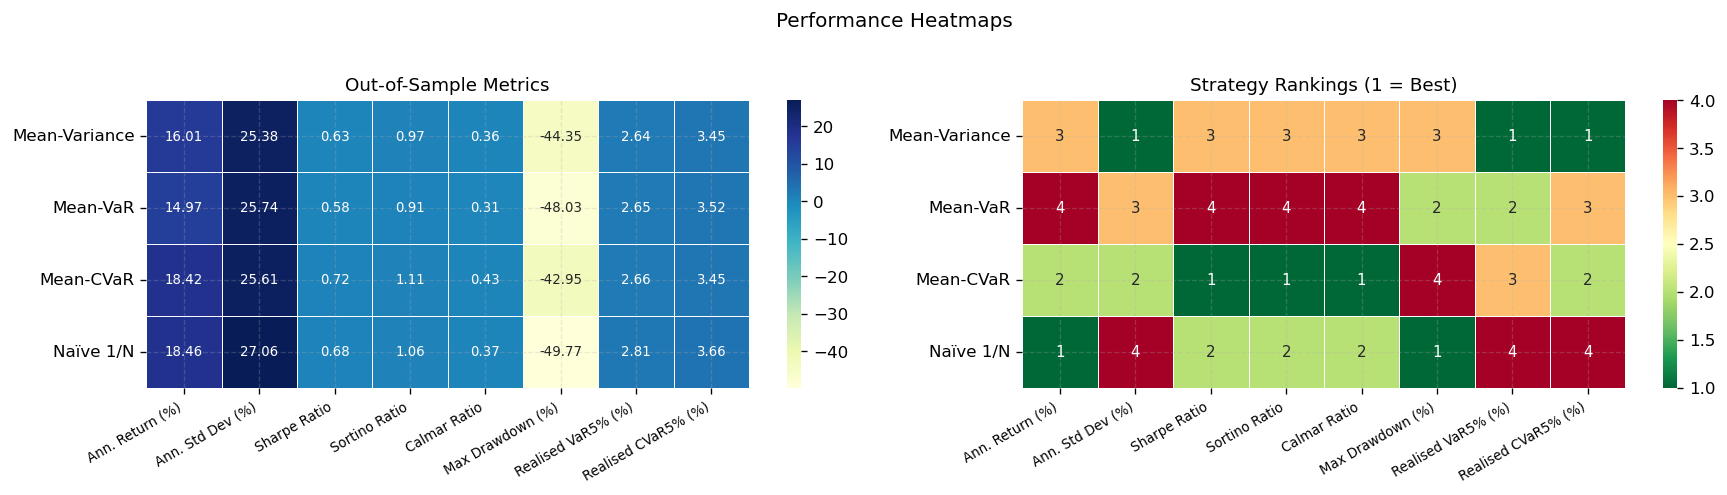

Average rank across all metrics (lower = better overall):
  Mean-CVaR                : 2.00
  Mean-Variance            : 2.25
  Naïve 1/N                : 2.50
  Mean-VaR                 : 3.25

In [12]:
# Rank each strategy on each metric (1 = best)
# For Max Drawdown, Realised VaR and CVaR: lower rank = better (ascending)
# For all other metrics: higher rank = better (descending)

lower_is_better = {'Ann. Std Dev (%)', 'Max Drawdown (%)',
                   'Realised VaR5% (%)', 'Realised CVaR5% (%)'}

rank_df = perf.copy()
for col in perf.columns:
    if col in lower_is_better:
        rank_df[col] = perf[col].rank(ascending=True)
    else:
        rank_df[col] = perf[col].rank(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Raw metrics
sns.heatmap(perf.astype(float), annot=True, fmt='.2f', cmap='YlGnBu',
            ax=axes[0], linewidths=0.4, annot_kws={'size': 8})
axes[0].set_title('Out-of-Sample Metrics')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right', fontsize=8)

# Rank heatmap (1=best)
sns.heatmap(rank_df.astype(float), annot=True, fmt='.0f', cmap='RdYlGn_r',
            ax=axes[1], linewidths=0.4, vmin=1, vmax=len(STRATEGY_KEYS),
            annot_kws={'size': 9})
axes[1].set_title('Strategy Rankings (1 = Best)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right', fontsize=8)

plt.suptitle('Performance Heatmaps', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

# Average rank
print('Average rank across all metrics (lower = better overall):')
avg_rank = rank_df.mean(axis=1).sort_values()
for strat, rk in avg_rank.items():
    print(f'  {strat:<25}: {rk:.2f}')

## 13. Discussion and Interpretation

---

### 13.1 Why Strategies Differ Out-of-Sample

All three optimised strategies use the **same empirical information set** (M-day return history) but minimise different risk measures. The key trade-offs are:

| Strategy | In-sample objective | Key vulnerability |
|---|---|---|
| Mean-Variance | Minimise variance | Estimation error in μ̂ and Σ̂ |
| Mean-VaR | Minimise empirical quantile | Non-convexity; local optima; ignores tail beyond VaR |
| Mean-CVaR | Minimise expected shortfall | More conservative; weights toward assets with fewer extreme losses |
| Naïve 1/N | — (no estimation) | Ignores all portfolio structure; no risk reduction beyond naive diversification |

---

### 13.2 Mean-Variance Portfolio

MV is theoretically optimal under joint normality but is sensitive to **estimation error in expected returns** (Michaud 1989). The no-short constraint (imposed here) partially regularises the optimiser. In practice, MV may produce lower Sharpe than 1/N when the estimation window M is short relative to N.

---

### 13.3 Mean-VaR Portfolio

VaR optimisation is **non-convex**: the empirical VaR is a step function of portfolio weights, with many local optima. SLSQP with random restarts finds a heuristic solution. Crucially, VaR is **not subadditive** — diversification can increase VaR when individual disaster probabilities are each below α but their combination exceeds α (as demonstrated in `risk_investment.ipynb`). This can lead to **concentrated positions** in the tail.

Expected out-of-sample: Mean-VaR may produce lower realised VaR but higher CVaR than Mean-CVaR, because it optimises only the quantile boundary and is blind to losses beyond it.

---

### 13.4 Mean-CVaR Portfolio

CVaR (= Expected Shortfall) is a **coherent risk measure** (Artzner et al. 1999): it satisfies subadditivity and convexity, making it a better incentive for diversification than VaR. The LP formulation (Rockafellar & Uryasev 2000) is exact and globally optimal.

CVaR portfolios tend to:
- Underweight assets with extreme left-tail events (even if rare)
- Produce lower realised CVaR and Sortino ratios out-of-sample
- Have more stable weights than MV under fat tails

This makes **Mean-CVaR the recommended strategy** for investors with tail-risk aversion (pension funds, insurers).

---

### 13.5 Naïve 1/N Benchmark

1/N requires zero estimation and often **outperforms optimised strategies** on Sharpe ratio in short-window settings (DeMiguel et al. 2007). The reason: estimation error in μ̂ is O(1/M), which for M=252 and annualised drifts of 10-35% is material. This "error-maximisation" problem is especially severe for unconstrained MV.

However, 1/N:
- Does **not** control VaR or CVaR
- Cannot adapt to changes in the risk environment
- Ignores the low correlation between tech and financials

---

### 13.6 Evaluation Criteria Choice (Justification)

We use **multiple criteria** because strategies optimise different objectives:

- **Sharpe / Sortino** evaluate risk-adjusted return: Sortino is more relevant for downside-focused strategies
- **Calmar Ratio** rewards drawdown control, important for practical implementation
- **Realised VaR / CVaR** directly test whether each strategy achieves its stated in-sample goal
- **Turnover** captures transaction costs: high turnover can erase apparent gains

A strategy that ranks well on average across all dimensions is more robust than one that dominates on a single metric.

---

### 13.7 Extensions and Improvements

1. **Shrinkage estimators** (Ledoit-Wolf): reduce covariance estimation error
2. **GARCH-based inputs**: improve variance forecasting in volatile regimes (as in Day 4)
3. **Transaction cost penalties**: include $c \|\mathbf{w}_t - \mathbf{w}_{t-1}\|_1$ in the objective
4. **Longer estimation windows / bootstrap resampling** (Michaud resampling): reduce sensitivity to in-sample outliers
5. **Factor models** (PCA, Fama-French): reduce dimensionality of Σ̂

---

### References

- Markowitz, H. (1952). *Portfolio Selection*. Journal of Finance, 7(1), 77–91.
- Michaud, R. (1989). *The Markowitz Optimisation Enigma*. FAJ, 45(1), 31–42.
- Rockafellar, R.T., & Uryasev, S. (2000). *Optimization of Conditional Value-at-Risk*. Journal of Risk, 2(3), 21–41.
- Artzner, P., Delbaen, F., Eber, J.M., & Heath, D. (1999). *Coherent Measures of Risk*. Mathematical Finance, 9(3), 203–228.
- DeMiguel, V., Garlappi, L., & Uppal, R. (2007). *Optimal Versus Naive Diversification*. Review of Financial Studies, 22(5), 1915–1953.